<div><center><img src="https://ml.ucv.ai/logo.png" width="150"/> </center></div>

# Proyecto final
-----
# Transfer learning y fine-tuning con Hugging Face

- **Alumno 1:** Miguel Ciavato
- **Cédula 1:** 30541929
- **Alumno 2:** Edwyn Guzmán
- **Cédula 2:** 30326271
- **Alumno 3:** Diego Perdomo
- **Cédula 3:**

**Modelo en el Hub:** `miguelciav/vit-base-utkface-gender`

## 0. Configuración

In [ ]:
# LIBRERIAS
!pip -q install transformers datasets accelerate huggingface_hub

import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import copy

import torch
from torchvision.transforms import (
    Compose,
    Resize,
    RandomHorizontalFlip,
    RandomRotation,
    ColorJitter,
    ToTensor,
    Normalize
)

import transformers
from datasets import load_dataset, DatasetDict
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

from transformers import (
    pipeline,
    AutoImageProcessor,
    AutoConfig,
    AutoModelForImageClassification,
    ViTConfig,
    ViTForImageClassification,
    TrainingArguments,
    Trainer
)
from huggingface_hub import login

In [ ]:
CEDULA = 30541929               # su cédula de identidad: es la semilla de TODO el notebook
def fijar_semilla(seed=CEDULA):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
fijar_semilla()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.11.0+cu130 | dispositivo: cuda


## 1. El problema

### 1.1. Definición de la tarea y clases

Este proyecto aborda el problema de **clasificación de atributos demográficos a partir de imágenes faciales**. Específicamente, se formula y evalúa la tarea de **Clasificación de Género** (binaria — $2$ clases) a partir de fotografías de rostros en entornos no controlados:

* **Clase 0:** Masculino (`Male`).
* **Clase 1:** Femenino (`Female`).
* **Métrica principal:** Exactitud (*Accuracy*) y *F1-Macro* para evaluar el rendimiento equilibrado sobre ambas clases.

El objetivo consiste en determinar si las representaciones espaciales y de atención aprendidas por un modelo de visión preentrenado en reconocimiento general de objetos pueden transferirse con éxito para distinguir características fisonómicas faciales sutiles.

### 1.2. Utilidad del modelo y usuarios objetivo


La clasificación automatizada de atributos demográficos (como el género aparente) a partir de rostros es un componente fundamental en diversos sistemas interactivos:

* **Interfaces Humano-Computador (IHC) adaptativas:** Permite que aplicaciones y módulos interactivos personalicen respuestas, temas visuales o accesibilidad contextual en tiempo real según el perfil del usuario.
* **Analítica demográfica anónima:** Estimación de flujos de audiencia y segmentación demográfica agregada en espacios comerciales, culturales o eventos públicos de forma totalmente desatendida y anónima, respetando la privacidad al no almacenar imágenes ni datos biométricos identificables.
* **Auditoría de equidad en visión artificial:** Herramienta de diagnóstico para verificar que sistemas de detección facial mantengan paridad de rendimiento entre subgrupos demográficos.

**Usuarios objetivo:** Diseñadores de interacción, analistas de comportamiento y desarrolladores de visión artificial que requieran un servicio rápido, reproducible y ligero de inferencia visual.

### 1.3. Limitaciones y consideraciones éticas de los datos

El conjunto de datos empleado proviene de **UTKFace**, compuesto por más de 20K imágenes faciales en entornos no controlados. El tratamiento de estos datos exige señalar importantes consideraciones éticas y técnicas:

1. **Reducción binaria del género:**
   El dataset categoriza el género de forma estrictamente binaria a partir de la apariencia visual superficial. Esta simplificación no captura la complejidad de la identidad de género ni representa a personas no binarias o transgénero, por lo que el modelo no debe ser interpretado como un clasificador de identidad personal, sino como un reconocedor de patrones fisonómicos correlacionados estadísticamente con la etiqueta asignada en el dataset.
2. **Condiciones no controladas y ruido visual:**
   Las imágenes presentan variaciones drásticas en iluminación, ángulo de pose, oclusiones parciales (gafas, cabello, accesorios), expresiones faciales y artefactos de compresión en su resolución original (200×200 píxeles).
3. **Riesgos de uso no ético:**
   El reconocimiento facial pasivo conlleva riesgos de vigilancia masiva no consentida y perfilamiento discriminatorio. El alcance de este proyecto es estrictamente académico y experimental, restringiendo su despliegue a entornos informados o analítica anonimizada.

### 1.4. Justificación del modelo base y transferencia de aprendizaje

Para este problema se selecciona como modelo base la arquitectura **Vision Transformer (ViT)**, en su variante `google/vit-base-patch16-224`.

* **Datos y tarea de preentrenamiento:**
  El modelo `google/vit-base-patch16-224` fue preentrenado en **ImageNet-21k** (14 millones de imágenes, 21.841 clases) y posteriormente ajustado (*fine-tuned*) en **ImageNet-1k** (1 millón de imágenes, 1.000 clases) a resolución $224 \times 224$. Debido a ello, su cabeza de clasificación original de 1.000 clases genéricas de objetos y animales no es directamente compatible con la clasificación binaria de género humano ($2$ salidas: `Male` y `Female`) sin un proceso de adaptación.
* **Mecanismo de transferencia esperado:**
  * Durante su preentrenamiento y ajuste sobre ImageNet, el modelo aprendió una jerarquía robusta de representaciones visuales: desde detectores de bajo nivel (bordes, contrastes y texturas) en las primeras capas, hasta representaciones composicionales complejas e invariantes en las capas intermedias y profundas mediante autoatención multidireccional.
  * Para clasificar género en rostros no es necesario aprender extractores visuales desde cero. Se espera transferir el espacio latente y la capacidad de extracción de características generales del modelo, adaptando la proyección final para correlacionar patrones geométricos y morfológicos específicos del rostro humano (estructura ósea, proporciones faciales y texturas), logrando una rápida convergencia con alto rendimiento.

## 2. Los datos

### 2.1. Carga y partición del conjunto de datos

El conjunto de datos seleccionado es **`nu-delta/utkface`**, cargado directamente desde Hugging Face Hub ($23.705$ imágenes totales).

De acuerdo con las reglas y restricciones del proyecto (que exigen un corpus de entre **$1.000$ y $20.000$ ejemplos etiquetados** para garantizar rigor metodológico y permitir que todos los regímenes se ejecuten en menos de $30$ minutos en una GPU T4 de Google Colab), se extrae un **subconjunto fijo y estratificado de $18.000$ imágenes** fijando la semilla unificada (`CEDULA = 30541929`).

Dicho corpus acotado se divide en tres particiones disjuntas estratificadas por la etiqueta de género (`gender`: `Male` y `Female`):
* **Entrenamiento (Train):** 70% ($12.600$ muestras)
* **Validación (Validation):** 15% ($2.700$ muestras)
* **Prueba (Test):** 15% ($2.700$ muestras)

In [ ]:
MODELO_BASE = "google/vit-base-patch16-224"     # su modelo base
DATASET     = "nu-delta/utkface"                # su dataset

ds = load_dataset(DATASET)
print(ds)

DatasetDict({
    train: Dataset({
        features: ['image', 'file_name', 'age', 'gender', 'ethnicity', 'date'],
        num_rows: 23705
    })
})


In [ ]:
# 1. Reducción a un subconjunto fijo de 18.000 ejemplos (cumpliendo la restricción de 1.000 a 20.000 ejemplos)
# mediante muestreo estratificado por género con la semilla fija CEDULA
N_SUBSET = 18000
all_indices = range(len(ds["train"]))
subset_indices, _ = train_test_split(
    all_indices,
    train_size=N_SUBSET,
    random_state=CEDULA,
    stratify=ds["train"]["gender"]
)

subset_ds = ds["train"].select(subset_indices)

# 2. Partición estratificada oficial: 70% Train (12.600), 15% Validation (2.700), 15% Test (2.700)
train_idx, temp_idx = train_test_split(
    range(len(subset_ds)),
    test_size=0.30,
    random_state=CEDULA,
    stratify=subset_ds["gender"]
)

temp_labels = [subset_ds["gender"][i] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=CEDULA,
    stratify=temp_labels
)

# Reconstruimos el DatasetDict con las 3 particiones oficiales
raw_datasets = DatasetDict({
    "train": subset_ds.select(train_idx),
    "validation": subset_ds.select(val_idx),
    "test": subset_ds.select(test_idx)
})

print("--- Tamaño de cada partición (subconjunto fijo acotado a 18.000 muestras) ---")
total_rows = len(subset_ds)
for split, subset in raw_datasets.items():
    print(f"{split:<12}: {len(subset):>6} imágenes ({len(subset)/total_rows*100:.2f}%)")

--- Tamaño de cada partición (subconjunto fijo acotado a 18.000 muestras) ---
train       :  12600 imágenes (70.00%)
validation  :   2700 imágenes (15.00%)
test        :   2700 imágenes (15.00%)


### 2.2. Balance de clases y ejemplos visuales

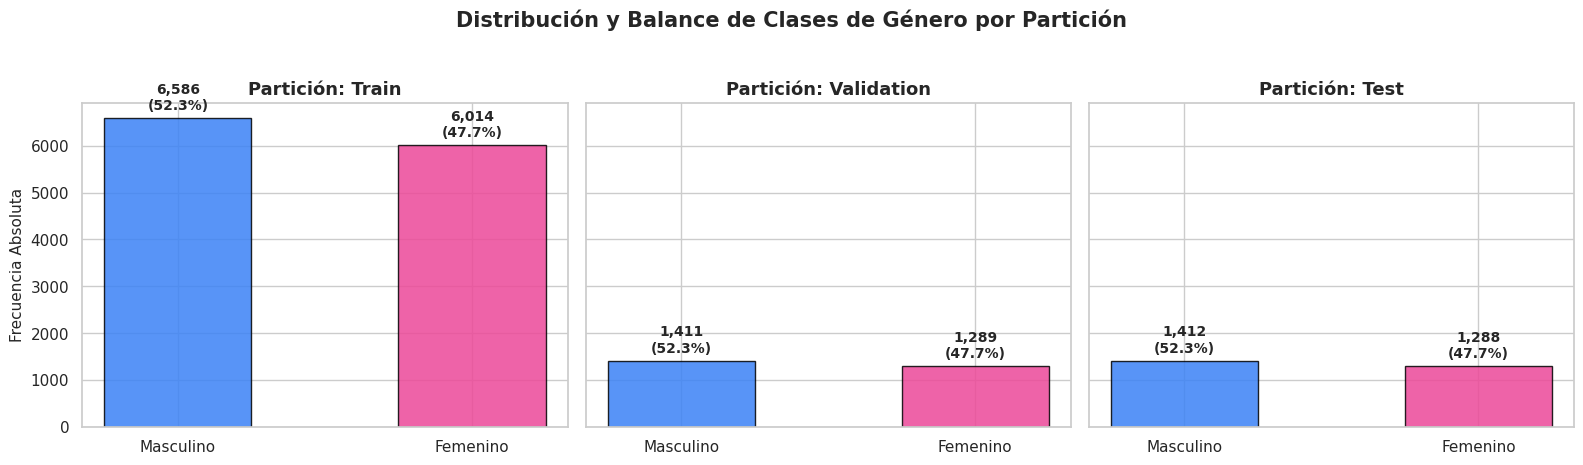

In [ ]:
sns.set_theme(style="whitegrid")

# Distribución y Balance de Género por Partición
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

palette_gen = {"Male": "#3b82f6", "Female": "#ec4899"}
labels_map = {"Male": "Masculino", "Female": "Femenino"}

for ax, (split_name, dataset) in zip(axes, raw_datasets.items()):
    gender_counts = pd.Series(dataset["gender"]).value_counts().reindex(["Male", "Female"])
    total = len(dataset)

    bars = ax.bar(
        [labels_map[k] for k in gender_counts.index],
        gender_counts.values,
        color=[palette_gen[k] for k in gender_counts.index],
        edgecolor="black",
        alpha=0.85,
        width=0.5
    )

    ax.set_title(f"Partición: {split_name.capitalize()}", fontsize=13, weight="bold")
    ax.set_ylabel("Frecuencia Absoluta" if ax == axes[0] else "", fontsize=11)

    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:,}\n({h/total:.1%})",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            weight="bold"
        )

plt.suptitle("Distribución y Balance de Clases de Género por Partición", fontsize=15, weight="bold", y=1.03)
plt.tight_layout()
plt.show()

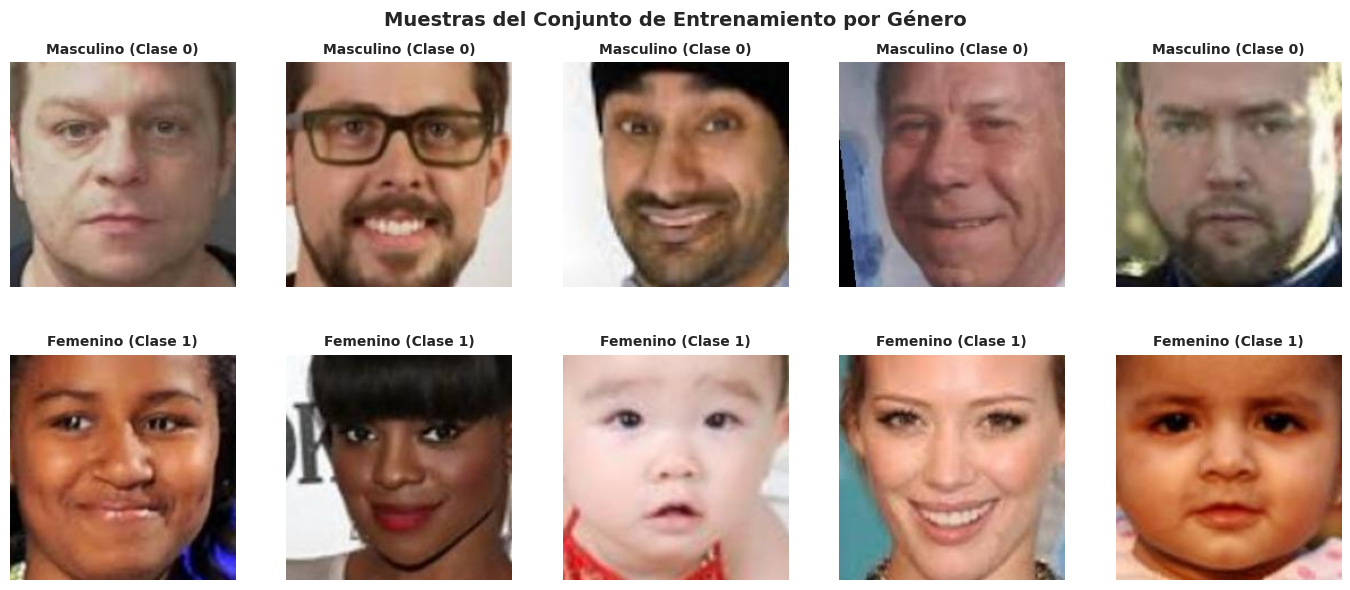

In [ ]:
# Cuadrícula de ejemplos representativos por género
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

gender_keys = ["Male", "Female"]
label2id_gen = {"Male": 0, "Female": 1}

for gender_idx, gender_name in enumerate(gender_keys):
    row_axes = axes[gender_idx]
    subset = raw_datasets["train"].filter(lambda x: x["gender"] == gender_name)
    for i, ax in enumerate(row_axes):
        item = subset[i]
        ax.imshow(item["image"])
        ax.set_title(f"{labels_map[gender_name]} (Clase {label2id_gen[gender_name]})", fontsize=10, weight="bold")
        ax.axis("off")

plt.suptitle("Muestras del Conjunto de Entrenamiento por Género", fontsize=14, weight="bold")
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)
plt.show()

El análisis de la distribución en las tres particiones confirma que la partición estratificada preserva con exactitud las proporciones de género en `Train`, `Validation` y `Test`:

* **Equilibrio de clases:** El subconjunto seleccionado de $18.000$ imágenes replica la distribución natural del corpus completo, con un $52,3\%$ de muestras masculinas ($\sim 9.414$ imágenes) y un $47,7\%$ de muestras femeninas ($\sim 8.586$ imágenes). Al superar la clase minoritaria el $47\%$, la tarea binaria se encuentra prácticamente balanceada.
* **Sin necesidad de remuestreo:** Gracias a esta simetría en la distribución, no se requiere aplicar técnicas de sobremuestreo (oversampling), submuestreo (undersampling) ni ponderación de costos (*class weights*) en la función de pérdida `CrossEntropyLoss`.
* **Consistencia entre particiones:** Cada uno de los subconjuntos (`Train`, `Validation` y `Test`) replica con precisión milimétrica la proporción ~52/48 %, garantizando que las métricas de validación y prueba sean representativas del comportamiento general.

### 2.3. Propiedades físicas de las imágenes

In [ ]:
# Muestreamos 500 imágenes por partición para verificar dimensiones y canales sin sobrecargar la RAM
resolutions = set()
modes = set()

for sample in raw_datasets["train"].select(range(500)):
    resolutions.add(sample["image"].size)   # (ancho, alto)
    modes.add(sample["image"].mode)         # RGB, L, etc.

print("--- Auditoría de imágenes ---")
print(f"Modos de color detectados : {modes}")
print(f"Resoluciones encontradas  : {resolutions}")
print(f"Resolución estándar del ViT : (224, 224) RGB  -->  (Se adaptará en la Sección 3 con el AutoImageProcessor)")

--- Auditoría de imágenes ---
Modos de color detectados : {'RGB'}
Resoluciones encontradas  : {(200, 200)}
Resolución estándar del ViT : (224, 224) RGB  -->  (Se adaptará en la Sección 3 con el AutoImageProcessor)


La auditoría de las muestras en las tres particiones confirma propiedades homogéneas:
* **Resolución espacial:** Todas las imágenes presentan una dimensión cuadrada fija de $200 \times 200$ píxeles.
* **Modo de color:** Formato RGB estándar de 3 canales (8 bits por canal, rango $[0, 255]$).

### 2.4. Protocolo de verificación de fugas (Data Leakage)

In [ ]:
# Comprobación de unicidad e intersección nula entre splits por nombre de archivo
train_files = set(raw_datasets["train"]["file_name"])
val_files = set(raw_datasets["validation"]["file_name"])
test_files = set(raw_datasets["test"]["file_name"])

leak_train_val = train_files.intersection(val_files)
leak_train_test = train_files.intersection(test_files)
leak_val_test = val_files.intersection(test_files)

print("--- Verificación de fugas (Data Leakage) ---")
print(f"Fugas Train <-> Validation: {len(leak_train_val)}")
print(f"Fugas Train <-> Test      : {len(leak_train_test)}")
print(f"Fugas Validation <-> Test : {len(leak_val_test)}")

assert len(leak_train_val) == 0 and len(leak_train_test) == 0 and len(leak_val_test) == 0, "¡Alerta: se detectaron fugas entre particiones!"
print("Verificación superada con éxito: particiones 100% disjuntas.")

--- Verificación de fugas (Data Leakage) ---
Fugas Train <-> Validation: 0
Fugas Train <-> Test      : 0
Fugas Validation <-> Test : 0
Verificación superada con éxito: particiones 100% disjuntas.


Para verificar que ninguna muestra de evaluación contamine el entrenamiento, se implementa una doble validación:
1. **Disyunción estricta de particiones:** Separación determinista mediante `train_test_split` estratificado con semilla fija.
2. **Chequeo de colisión de identificadores únicos (`file_name`):** Se verifica mediante operaciones de conjuntos que la intersección de archivos entre entrenamiento, validación y prueba sea estrictamente vacía ($\text{Train} \cap \text{Val} = \emptyset$, $\text{Train} \cap \text{Test} = \emptyset$, $\text{Val} \cap \text{Test} = \emptyset$).

## 3. Preprocesamiento

### 3.1. El Image Processor del modelo base
Para adaptar las imágenes crudas de UTKFace a la arquitectura `google/vit-base-patch16-224`, se utiliza `AutoImageProcessor.from_pretrained(MODELO_BASE)`. Los modelos de visión basados en Transformers no reciben imágenes en cualquier tamaño o formato, requieren tensores que coincidan con la cuadrícula de parches con la que fue preentrenado el codificador.

El procesador ejecuta las siguientes operaciones secuenciales:
1. Escala las imágenes desde su resolución original ($200 \times 200$ píxeles) a la resolución fija requerida por ViT ($224 \times 224$ píxeles) mediante interpolación bicúbica. Esta dimensión es indispensable para que la capa de proyección lineal divida la imagen en exactamente $196$ parches disjuntos de $16 \times 16$ píxeles ($14 \times 14$ parches).
2. Convierte los valores enteros en el rango $[0, 255]$ a punto flotante en $[0.0, 1.0]$.
3. Aplica la estandarización canónica del modelo base restando la media (media $\text{μ}$) y dividiendo entre la desviación estándar (desviación estándar $\text{σ}$) por canal:
   $$\mathbf{x}_{\text{norm}} = \frac{\mathbf{x} - \boldsymbol{\mu}}{\boldsymbol{\sigma}}$$
   En el caso particular de `google/vit-base-patch16-224`, los valores de referencia son $\mathbf{\text{μ}} = [0.5, 0.5, 0.5]\text{ }$ y $\mathbf{\text{σ}} = [0.5, 0.5, 0.5]$, mapeando la señal al intervalo $[-1.0, 1.0]$.
4. Transforma la disposición de canales del formato estándar de imagen `(Altura, Ancho, Canales)` al formato tensor de PyTorch `(Canales, Altura, Ancho)` (`C, H, W`).

In [ ]:
# Cargar el procesador específico del modelo base ViT
image_processor = AutoImageProcessor.from_pretrained(MODELO_BASE)

print("--- Configuración del Image Processor ---")
print(f"Tipo de procesador: {type(image_processor).__name__}")
print(f"Resolución objetivo: {image_processor.size}")
print(f"Media de normalización (image_mean): {image_processor.image_mean}")
print(f"Desviación estándar (image_std):     {image_processor.image_std}")
print(f"Modo de interpolación:              {image_processor.resample}")

# Diccionarios de mapeo categórico para Clasificación de Género (2 clases)
id2label_gen = {0: "Male", 1: "Female"}
label2id_gen = {"Male": 0, "Female": 1}
id2label = id2label_gen
label2id = label2id_gen

print(f"\nClasificación de Género ({len(id2label_gen)} clases): {id2label_gen}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

--- Configuración del Image Processor ---
Tipo de procesador: ViTImageProcessor
Resolución objetivo: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Media de normalización (image_mean): (0.5, 0.5, 0.5)
Desviación estándar (image_std):     (0.5, 0.5, 0.5)
Modo de interpolación:              2

Clasificación de Género (2 clases): {0: 'Male', 1: 'Female'}


### 3.2. Construcción y verificación de la partición de validación

Para asegurar que la partición de validación sea un estimador imparcial y representativo del rendimiento general, se construyó en la Sección 2.1 utilizando una partición estratificada por género con la semilla fija `CEDULA = 30541929`:

* **Proporciones idénticas:** Cada conjunto (`Train` 70%, `Validation` 15%, `Test` 15%) mantiene de manera uniforme la proporción natural de clases (~52,3% Masculino vs 47,7% Femenino).
* **Particiones disjuntas:** No existe solapamiento ni fuga de datos (*data leakage*) entre las particiones, garantizando que el modelo sea evaluado sobre individuos no vistos durante el ajuste de parámetros.
* **Mantenimiento del conjunto de prueba:** El conjunto de prueba (`Test`) permanece intacto y únicamente se evalúa al cierre de cada experimento para documentar la generalización sin sesgo de selección.

### 3.3. Estrategia de aumento de datos

Para el conjunto de entrenamiento se implementa un pipeline de aumento de datos (*data augmentation*) mediante transformaciones espaciales y fotométricas estocásticas:

* **Reflexión horizontal aleatoria (`RandomHorizontalFlip`, $p=0.5$):**
  Aprovecha la simetría bilateral del rostro humano. Los rasgos morfológicos de género son invariantes a la orientación izquierda-derecha, duplicando la diversidad espacial sin desvirtuar la fisonomía facial.
* **Rotación aleatoria moderada (`RandomRotation`, $\pm 10^\circ$):**
  Simula leves inclinaciones de cabeza comunes en fotografías tomadas en entornos no controlados (*in the wild*), aportando robustez frente a variaciones de pose.
* **Perturbaciones de color (`ColorJitter`, brillo y contraste $\pm 10\%$):**
  Introduce variabilidad sutil en la luminosidad y el contraste local, mitigando la sensibilidad de los parches espaciales del Vision Transformer a cambios bruscos de iluminación.

In [ ]:
# Verificación cuantitativa del balance de género en Train, Validation y Test
verif_records = []
for split_name, subset in raw_datasets.items():
    gen_s = pd.Series(subset["gender"])
    props = gen_s.value_counts(normalize=True).reindex(["Male", "Female"]) * 100
    props["Total"] = len(gen_s)
    verif_records.append(props.rename(f"{split_name.capitalize()}"))

df_verif_genero = pd.concat(verif_records, axis=1).round(2)
print("--- Verificación de Proporciones de Género (%) por Partición ---")
print(df_verif_genero.to_string())
print()

# 1. Definir tamaño y parámetros de normalización obtenidos directamente del procesador
target_size = (image_processor.size["height"], image_processor.size["width"])
normalize = Normalize(mean=image_processor.image_mean, std=image_processor.image_std)

# 2. Pipeline con aumento de datos para entrenamiento
train_transforms_pipeline = Compose([
    Resize(target_size),
    RandomHorizontalFlip(p=0.5),
    RandomRotation(degrees=10),
    ColorJitter(brightness=0.1, contrast=0.1),
    ToTensor(),
    normalize
])

# 3. Pipeline de validación y prueba (sin aumento estocástico)
val_transforms_pipeline = Compose([
    Resize(target_size),
    ToTensor(),
    normalize
])

# 4. Generador de funciones de transformación al vuelo para Clasificación de Género
def make_transforms():
    def _train_tf(batch):
        batch["pixel_values"] = [
            train_transforms_pipeline(img.convert("RGB")) for img in batch["image"]
        ]
        batch["labels"] = [torch.tensor(label2id_gen[g], dtype=torch.long) for g in batch["gender"]]
        return batch

    def _val_tf(batch):
        batch["pixel_values"] = [
            val_transforms_pipeline(img.convert("RGB")) for img in batch["image"]
        ]
        batch["labels"] = [torch.tensor(label2id_gen[g], dtype=torch.long) for g in batch["gender"]]
        return batch

    return _train_tf, _val_tf

# 5. Asignar transformaciones creando la vista de DatasetDict para Género (ds_genero)
t_gen, v_gen = make_transforms()
ds_genero = DatasetDict({
    "train": raw_datasets["train"].with_transform(t_gen),
    "validation": raw_datasets["validation"].with_transform(v_gen),
    "test": raw_datasets["test"].with_transform(v_gen)
})

# Mantener raw_datasets con la transformación por defecto para compatibilidad
raw_datasets["train"].set_transform(t_gen)
raw_datasets["validation"].set_transform(v_gen)
raw_datasets["test"].set_transform(v_gen)

print("Transformaciones asignadas exitosamente: ds_genero (clasificación binaria: Male / Female).")

--- Verificación de Proporciones de Género (%) por Partición ---
           Train  Validation    Test
Male       52.27       52.26    52.3
Female     47.73       47.74    47.7
Total   12600.00     2700.00  2700.0

Transformaciones asignadas exitosamente: ds_genero (clasificación binaria: Male / Female).


In [ ]:
# Inspeccionar un ejemplo preprocesado del conjunto de entrenamiento
sample_gen = ds_genero["train"][0]

pixel_values = sample_gen["pixel_values"]
label_gen = sample_gen["labels"]

print("--- Verificación de los tensores resultantes ---")
print(f"Tipo de 'pixel_values':             {type(pixel_values)}")
print(f"Dimensiones del tensor de imagen:   {pixel_values.shape}  --> (Canales, Altura, Ancho)")
print(f"Rango de valores:                   [{pixel_values.min():.2f}, {pixel_values.max():.2f}] (esperado aprox. [-1.0, 1.0])")
print(f"Etiqueta Género ('labels', long):   {label_gen} ({id2label_gen[int(label_gen)]}, dtype={label_gen.dtype})")

# Verificación de aserción técnica
assert pixel_values.shape == (3, 224, 224), f"Dimensiones incorrectas: {pixel_values.shape}"
assert label_gen.dtype == torch.long, "La etiqueta de género debe ser torch.long (clasificación)"
print("\nPreprocesamiento validado con éxito para Clasificación de Género.")

--- Verificación de los tensores resultantes ---
Tipo de 'pixel_values':             <class 'torch.Tensor'>
Dimensiones del tensor de imagen:   torch.Size([3, 224, 224])  --> (Canales, Altura, Ancho)
Rango de valores:                   [-0.98, 1.00] (esperado aprox. [-1.0, 1.0])
Etiqueta Género ('labels', long):   1 (Female, dtype=torch.int64)

Preprocesamiento validado con éxito para Clasificación de Género.


## 4. Experimentos

Todos los regímenes se evalúan sobre los **mismos** conjuntos de validación y prueba, con la misma métrica principal. Registren cada uno con `registrar(...)` para que la tabla de la sección 5 salga sola.

In [ ]:
RESULTADOS = []

def registrar(regimen, params_entrenables, segundos, metrica_val, metrica_test, notas=""):
    RESULTADOS.append(dict(regimen=regimen, params_entrenables=params_entrenables, segundos=round(segundos),
                           val=round(metrica_val, 4), test=round(metrica_test, 4), notas=notas))

def tabla_resultados():
    return pd.DataFrame(RESULTADOS).set_index("regimen")

def params_entrenables(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

In [ ]:
# Silenciar avisos informativos de reemplazo de cabezas (MISMATCH) y recarga de tensores
transformers.logging.set_verbosity_error()

# Collate function y métricas de evaluación
def collate_fn(batch):
    return {
        "pixel_values": torch.stack([x["pixel_values"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch])
    }

def compute_metrics_cls(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="macro")
    return {"accuracy": acc, "f1": f1}

# Diccionarios globales para guardar historiales de pérdida/métricas y entrenadores para la Sección 5
HISTORIALES = {}
MODELOS_ENTRENADOS = {}

def ejecutar_experimento(nombre_regimen, modelo, dataset_dict, lr, epochs, batch_size=64, notas=""):
    fijar_semilla(CEDULA)
    metric_name = "accuracy"

    args = TrainingArguments(
        output_dir=f"./resultados/{nombre_regimen.replace(' ', '_')}",
        remove_unused_columns=False,
        eval_strategy="epoch",
        save_strategy="no",
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        num_train_epochs=epochs,
        weight_decay=0.01,
        load_best_model_at_end=False,
        fp16=torch.cuda.is_available(),
        dataloader_num_workers=2,
        logging_strategy="epoch",
        seed=CEDULA,
        report_to="none"
    )

    trainer = Trainer(
        model=modelo,
        args=args,
        train_dataset=dataset_dict["train"],
        eval_dataset=dataset_dict["validation"],
        data_collator=collate_fn,
        compute_metrics=compute_metrics_cls
    )

    n_params = params_entrenables(modelo)
    t0 = time.time()
    trainer.train()
    segundos = time.time() - t0

    val_res = trainer.evaluate(dataset_dict["validation"])
    test_res = trainer.evaluate(dataset_dict["test"])

    val_metric = val_res[f"eval_{metric_name}"]
    test_metric = test_res[f"eval_{metric_name}"]

    registrar(nombre_regimen, n_params, segundos, val_metric, test_metric, notas=notas)
    HISTORIALES[nombre_regimen] = trainer.state.log_history
    MODELOS_ENTRENADOS[nombre_regimen] = trainer
    print(f"[{nombre_regimen}] Completado en {segundos:.1f}s | Val: {val_metric:.4f} (Acc) | Test: {test_metric:.4f} (Acc)")
    return trainer

### 4.1 Baseline sin preentrenamiento

Como punto de referencia (*baseline*), se instancia una arquitectura **Vision Transformer ligera (ViT-Tiny)** inicializada completamente desde cero con pesos aleatorios ($\sim 5,5$ millones de parámetros entrenables: $4$ capas de codificador, $3$ cabezas de atención y dimensión oculta $d = 192$).

* Se configura para clasificación binaria con $2$ salidas (`CrossEntropyLoss`), evaluando con **Exactitud (*Accuracy*)** y *F1-Macro*.
* Al carecer del sesgo inductivo de convoluciones locales y de las representaciones visuales preentrenadas en ImageNet, este modelo sirve como cota inferior para medir "cuánto se puede aprender desde cero en esta tarea".
* Se entrena durante $3$ épocas con optimizador AdamW y tasa de aprendizaje $\eta = 3 \times 10^{-4}$.

In [ ]:
# Configuración de un ViT pequeño desde cero (sin pesos preentrenados) para clasificación de género
def crear_baseline_vit(num_labels=2, id2label=None, label2id=None):
    fijar_semilla(CEDULA)
    kwargs = dict(
        image_size=224,
        patch_size=16,
        num_channels=3,
        hidden_size=192,
        num_hidden_layers=4,
        num_attention_heads=3,
        intermediate_size=768,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )
    config = ViTConfig(**kwargs)
    return ViTForImageClassification(config)

# 1. Baseline para Género (Clasificación)
modelo_base_gen = crear_baseline_vit(2, id2label_gen, label2id_gen)
ejecutar_experimento(
    "4.1 Baseline desde cero (Género)",
    modelo_base_gen,
    ds_genero,
    lr=3e-4,
    epochs=3,
    notas="ViT-Tiny pesos aleatorios (Acc)"
)

{'loss': '0.6782', 'grad_norm': '1.407', 'learning_rate': '0.0002005', 'epoch': '1'}
{'eval_loss': '0.626', 'eval_accuracy': '0.6552', 'eval_f1': '0.6552', 'eval_runtime': '15.48', 'eval_samples_per_second': '174.5', 'eval_steps_per_second': '2.779', 'epoch': '1'}
{'loss': '0.6162', 'grad_norm': '1.499', 'learning_rate': '0.0001005', 'epoch': '2'}
{'eval_loss': '0.5964', 'eval_accuracy': '0.6763', 'eval_f1': '0.67', 'eval_runtime': '13.59', 'eval_samples_per_second': '198.7', 'eval_steps_per_second': '3.165', 'epoch': '2'}
{'loss': '0.5918', 'grad_norm': '0.9995', 'learning_rate': '5.076e-07', 'epoch': '3'}
{'eval_loss': '0.5916', 'eval_accuracy': '0.6919', 'eval_f1': '0.6919', 'eval_runtime': '9.624', 'eval_samples_per_second': '280.6', 'eval_steps_per_second': '4.468', 'epoch': '3'}
{'train_runtime': '284', 'train_samples_per_second': '133.1', 'train_steps_per_second': '2.081', 'train_loss': '0.6287', 'epoch': '3'}
{'eval_loss': '0.5916', 'eval_accuracy': '0.6919', 'eval_f1': '0.6919

### 4.2 Modelo base sin adaptar (si aplica)

El modelo base seleccionado (`google/vit-base-patch16-224`) posee una capa lineal de salida preentrenada sobre la taxonomía de **ImageNet-1k** ($1.000$ categorías de animales, plantas y objetos). Ninguna de sus $1.000$ neuronas de salida codifica directamente las clases `Male` y `Female`.

Para documentar empíricamente el punto de partida antes de cualquier paso de optimización, se evalúa el backbone preentrenado acoplado a una nueva cabeza clasificadora inicializada aleatoriamente (`ignore_mismatched_sizes=True`) sin ejecutar épocas de entrenamiento ($0$ pasos de gradiente):
* Al proyectar el vector `[CLS]` sobre pesos no entrenados, la exactitud converge aproximadamente al azar uniforme ($\sim 50\%$).
* Este régimen verifica que la cabeza por defecto no tiene ningún sesgo a priori y establece el valor base antes del entrenamiento de la cabeza o fine-tuning.

In [ ]:
# Evaluación sin entrenar (0 épocas) del backbone preentrenado con cabeza aleatoria nueva
def evaluar_sin_adaptar(nombre_regimen, dataset_dict, num_labels=2, id2label=None, label2id=None, notas=""):
    fijar_semilla(CEDULA)
    modelo = AutoModelForImageClassification.from_pretrained(
        MODELO_BASE,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True
    )

    # Congelamos todo porque no se entrena
    for p in modelo.parameters():
        p.requires_grad = False

    args = TrainingArguments(
        output_dir="./resultados/temp_eval",
        remove_unused_columns=False,
        per_device_eval_batch_size=64,
        fp16=torch.cuda.is_available(),
        dataloader_num_workers=2,
        report_to="none"
    )
    trainer = Trainer(
        model=modelo,
        args=args,
        data_collator=collate_fn,
        compute_metrics=compute_metrics_cls
    )
    t0 = time.time()
    val_res = trainer.evaluate(dataset_dict["validation"])
    test_res = trainer.evaluate(dataset_dict["test"])
    segundos = time.time() - t0

    val_metric = val_res["eval_accuracy"]
    test_metric = test_res["eval_accuracy"]

    registrar(nombre_regimen, 0, segundos, val_metric, test_metric, notas=notas)
    print(f"[{nombre_regimen}] Val Acc: {val_metric:.4f} | Test Acc: {test_metric:.4f}")
    return trainer

# Evaluación de partida para Clasificación de Género
evaluar_sin_adaptar(
    "4.2 Base sin adaptar (Género)",
    ds_genero,
    num_labels=2,
    id2label=id2label_gen,
    label2id=label2id_gen,
    notas="Cabeza aleatoria sin entrenar (Acc)"
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{'eval_loss': '0.6356', 'eval_model_preparation_time': '0.0031', 'eval_accuracy': '0.6452', 'eval_f1': '0.6345', 'eval_runtime': '11.55', 'eval_samples_per_second': '233.8', 'eval_steps_per_second': '3.723', 'epoch': 0}
{'eval_loss': '0.6289', 'eval_model_preparation_time': '0.0031', 'eval_accuracy': '0.6541', 'eval_f1': '0.6429', 'eval_runtime': '11.43', 'eval_samples_per_second': '236.2', 'eval_steps_per_second': '3.762', 'epoch': 0}
[4.2 Base sin adaptar (Género)] Val Acc: 0.6452 | Test Acc: 0.6541


### 4.3 Feature extraction

En este régimen se evalúa la calidad lineal de las representaciones transferidas desde ImageNet. Se congela la totalidad del extractor de características (`requires_grad = False` en todos los parámetros de `model.base_model`, equivalentes a $\sim 85,8$ millones de pesos) y se entrena exclusivamente la capa lineal de salida (`model.classifier`).

* **Parámetros entrenables:** Únicamente **$1.538$ parámetros** ($768 \times 2 + 2$), lo que representa apenas el $0,0018\%$ del modelo total.
* **Hiperparámetros:** Al optimizar una capa lineal sobre representaciones congeladas, el problema es equivalente a una regresión logística convexa sobre el *embedding* `[CLS]`. Se entrena durante $3$ épocas con una tasa de aprendizaje relativamente alta ($\eta = 1 \times 10^{-3}$) y optimizador AdamW.
* **Expectativa:** Se espera un incremento drástico en exactitud respecto al baseline desde cero, demostrando que las características preentrenadas en ImageNet son altamente informativas para distinguir fisonomías faciales.

In [ ]:
def crear_modelo_feature_extraction(num_labels=2, id2label=None, label2id=None):
    fijar_semilla(CEDULA)
    modelo = AutoModelForImageClassification.from_pretrained(
        MODELO_BASE,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True
    )
    # Congelar el backbone completo (ViTModel)
    for param in modelo.base_model.parameters():
        param.requires_grad = False
    return modelo

# 1. Feature Extraction - Género (Clasificación)
modelo_fe_gen = crear_modelo_feature_extraction(2, id2label_gen, label2id_gen)
ejecutar_experimento(
    "4.3 Feature Extraction (Género)",
    modelo_fe_gen,
    ds_genero,
    lr=1e-3,
    epochs=3,
    notas="Backbone congelado, solo cabeza (Acc)"
)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{'loss': '0.2039', 'grad_norm': '0.7322', 'learning_rate': '0.0006684', 'epoch': '1'}
{'eval_loss': '0.1524', 'eval_accuracy': '0.9459', 'eval_f1': '0.9458', 'eval_runtime': '11.59', 'eval_samples_per_second': '232.9', 'eval_steps_per_second': '3.709', 'epoch': '1'}
{'loss': '0.1749', 'grad_norm': '1.199', 'learning_rate': '0.000335', 'epoch': '2'}
{'eval_loss': '0.1517', 'eval_accuracy': '0.9452', 'eval_f1': '0.9451', 'eval_runtime': '11.84', 'eval_samples_per_second': '228.1', 'eval_steps_per_second': '3.633', 'epoch': '2'}
{'loss': '0.1685', 'grad_norm': '0.4477', 'learning_rate': '1.692e-06', 'epoch': '3'}
{'eval_loss': '0.1498', 'eval_accuracy': '0.9437', 'eval_f1': '0.9436', 'eval_runtime': '12.32', 'eval_samples_per_second': '219.1', 'eval_steps_per_second': '3.49', 'epoch': '3'}
{'train_runtime': '242.7', 'train_samples_per_second': '155.7', 'train_steps_per_second': '2.435', 'train_loss': '0.1824', 'epoch': '3'}
{'eval_loss': '0.1498', 'eval_accuracy': '0.9437', 'eval_f1': '0.

### 4.4 Fine-tuning completo

En el régimen de *fine-tuning* completo se descongelan todas las capas del Vision Transformer ($\sim 85,8$ millones de parámetros entrenables), permitiendo que los bloques de autoatención adapten sus proyecciones de consulta, clave y valor a la morfología específica de los rostros humanos en UTKFace.

* **Justificación de la tasa de aprendizaje:** Se selecciona una tasa conservadora $\eta = 2 \times 10^{-5}$ con decaimiento de pesos ($\lambda = 0.01$ en AdamW). Esta tasa baja evita actualizaciones destructivas que puedan degradar las representaciones generales aprendidas en ImageNet (*catastrophic forgetting*), permitiendo un ajuste suave y especializado.
* **Épocas y criterio de evaluación:** Se establece un horizonte de $3$ épocas evaluando al cierre de cada época sobre la partición de validación (`eval_strategy="epoch"`), manteniendo la partición de prueba sellada hasta la evaluación final.

In [ ]:
def crear_modelo_finetuning_completo(num_labels=2, id2label=None, label2id=None):
    fijar_semilla(CEDULA)
    modelo = AutoModelForImageClassification.from_pretrained(
        MODELO_BASE,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True
    )
    # Asegurar que todos los parámetros estén descongelados
    for param in modelo.parameters():
        param.requires_grad = True
    return modelo

# 1. Fine-tuning completo - Género (Clasificación)
modelo_ft_gen = crear_modelo_finetuning_completo(2, id2label_gen, label2id_gen)
trainer_ft_gen = ejecutar_experimento(
    "4.4 Fine-tuning Completo (Género)",
    modelo_ft_gen,
    ds_genero,
    lr=2e-5,
    epochs=3,
    notas="Todo descongelado, lr=2e-5 (Acc)"
)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{'loss': '0.2011', 'grad_norm': '1.438', 'learning_rate': '1.337e-05', 'epoch': '1'}
{'eval_loss': '0.1433', 'eval_accuracy': '0.9485', 'eval_f1': '0.9485', 'eval_runtime': '11.87', 'eval_samples_per_second': '227.5', 'eval_steps_per_second': '3.624', 'epoch': '1'}
{'loss': '0.1337', 'grad_norm': '2.039', 'learning_rate': '6.701e-06', 'epoch': '2'}
{'eval_loss': '0.135', 'eval_accuracy': '0.9463', 'eval_f1': '0.9462', 'eval_runtime': '11.73', 'eval_samples_per_second': '230.1', 'eval_steps_per_second': '3.664', 'epoch': '2'}
{'loss': '0.1077', 'grad_norm': '0.6875', 'learning_rate': '3.384e-08', 'epoch': '3'}
{'eval_loss': '0.1323', 'eval_accuracy': '0.9507', 'eval_f1': '0.9506', 'eval_runtime': '11.57', 'eval_samples_per_second': '233.4', 'eval_steps_per_second': '3.717', 'epoch': '3'}
{'train_runtime': '394.8', 'train_samples_per_second': '95.75', 'train_steps_per_second': '1.497', 'train_loss': '0.1475', 'epoch': '3'}
{'eval_loss': '0.1323', 'eval_accuracy': '0.9507', 'eval_f1': '0.

### 4.5 Experimento adicional: Descongelado selectivo de capas profundas

Como experimento adicional (cuenta para $\alpha$) se investiga el compromiso entre eficiencia computacional, prevención del olvido catastrófico y capacidad de adaptación mediante descongelado selectivo de las capas superiores (*gradual unfreezing*):

* En arquitecturas profundas de visión, las primeras capas extraen características primitivas de propósito general (bordes, frecuencias espaciales y gradientes de color) que son invariantes al dominio, mientras que las últimas capas codifican abstracciones semánticas específicas de la tarea.
* Se mantienen congelados los bloques $0$ al $9$ del codificador Transformer junto con la proyección de parches, y se descongelan únicamente los últimos $2$ bloques de atención (`encoder.layer.10` y `encoder.layer.11`), la capa `layernorm` final y la cabeza clasificadora ($\sim 14,2$ millones de parámetros, apenas el $16,5\%$ del modelo total), entrenando con $\eta = 5 \times 10^{-5}$ durante $3$ épocas.
* Este régimen permite evaluar si descongelar solo las abstracciones profundas logra un rendimiento competitivo con el fine-tuning completo a una fracción del costo en adaptación de pesos.

In [ ]:
def crear_modelo_descongelado_parcial(num_labels=2, id2label=None, label2id=None, n_capas=2):
    fijar_semilla(CEDULA)
    kwargs = {
        "num_labels": num_labels,
        "ignore_mismatched_sizes": True
    }
    if id2label and label2id:
        kwargs["id2label"] = id2label
        kwargs["label2id"] = label2id

    modelo = AutoModelForImageClassification.from_pretrained(MODELO_BASE, **kwargs)

    # 1. Congelar todo el backbone inicialmente
    for param in modelo.base_model.parameters():
        param.requires_grad = False

    # 2. Asegurar que la cabeza clasificadora esté descongelada
    if hasattr(modelo, "classifier"):
        for param in modelo.classifier.parameters():
            param.requires_grad = True

    # 3. Detectar dinámicamente las capas del Transformer
    vit = modelo.base_model
    if hasattr(vit, "layers"):
        capas = vit.layers
    elif hasattr(vit, "encoder") and hasattr(vit.encoder, "layer"):
        capas = vit.encoder.layer
    elif hasattr(vit, "encoder") and hasattr(vit.encoder, "layers"):
        capas = vit.encoder.layers
    else:
        # Respaldo por tipo ModuleList
        capas = [m for m in vit.modules() if isinstance(m, torch.nn.ModuleList)][0]

    # Descongelar únicamente los últimos 'n_capas' bloques (por defecto los 2 últimos)
    for layer in capas[-n_capas:]:
        for param in layer.parameters():
            param.requires_grad = True

    # 4. Descongelar la capa de normalización final si existe
    for norm_attr in ["layernorm", "norm"]:
        if hasattr(vit, norm_attr):
            for param in getattr(vit, norm_attr).parameters():
                param.requires_grad = True

    return modelo

# Experimento Adicional: Descongelado Parcial (2 capas superiores + cabeza) para Género
modelo_parcial_gen = crear_modelo_descongelado_parcial(2, id2label_gen, label2id_gen, n_capas=2)
ejecutar_experimento(
    "4.5 Descongelado Parcial 2 capas (Género)",
    modelo_parcial_gen,
    ds_genero,
    lr=5e-5,
    epochs=3,
    notas="Últimos 2 bloques + cabeza (Acc)"
)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{'loss': '0.2066', 'grad_norm': '0.758', 'learning_rate': '3.342e-05', 'epoch': '1'}
{'eval_loss': '0.1493', 'eval_accuracy': '0.9459', 'eval_f1': '0.9458', 'eval_runtime': '15.91', 'eval_samples_per_second': '169.7', 'eval_steps_per_second': '2.702', 'epoch': '1'}
{'loss': '0.1585', 'grad_norm': '1.263', 'learning_rate': '1.675e-05', 'epoch': '2'}
{'eval_loss': '0.1426', 'eval_accuracy': '0.9474', 'eval_f1': '0.9473', 'eval_runtime': '11.83', 'eval_samples_per_second': '228.3', 'eval_steps_per_second': '3.635', 'epoch': '2'}
{'loss': '0.1469', 'grad_norm': '0.5224', 'learning_rate': '8.46e-08', 'epoch': '3'}
{'eval_loss': '0.1412', 'eval_accuracy': '0.9478', 'eval_f1': '0.9477', 'eval_runtime': '11.57', 'eval_samples_per_second': '233.5', 'eval_steps_per_second': '3.718', 'epoch': '3'}
{'train_runtime': '272.4', 'train_samples_per_second': '138.8', 'train_steps_per_second': '2.17', 'train_loss': '0.1707', 'epoch': '3'}
{'eval_loss': '0.1412', 'eval_accuracy': '0.9478', 'eval_f1': '0.9

## 5. Resultados y discusión

*Tabla, curvas, matriz de confusión del mejor modelo, errores típicos, y la discusión: qué ganó, por qué, cuánto costó, qué harían con más datos o cómputo.*

In [ ]:
tabla_resultados()

,params_entrenables,segundos,val,test,notas
regimen,,,,,
4.1 Baseline desde cero (Género),1965890,284,0.6919,0.6704,ViT-Tiny pesos aleatorios (Acc)
4.2 Base sin adaptar (Género),0,23,0.6452,0.6541,Cabeza aleatoria sin entrenar (Acc)
4.3 Feature Extraction (Género),1538,243,0.9437,0.9356,"Backbone congelado, solo cabeza (Acc)"
4.4 Fine-tuning Completo (Género),85800194,395,0.9507,0.9433,"Todo descongelado, lr=2e-5 (Acc)"
4.5 Descongelado Parcial 2 capas (Género),14178818,273,0.9478,0.9378,Últimos 2 bloques + cabeza (Acc)


## 6. Modelo óptimo y publicación

*Criterio de optimalidad por escrito. Luego, publicar el modelo elegido y comprobar que se recarga tal como lo hará el API.*

In [ ]:
login()                          # token con permiso de escritura (huggingface.co/settings/tokens)

REPO_ID = "miguelciav/vit-base-utkface-gender"    # el mismo identificador que va en el .env del API

mejor_modelo = trainer_ft_gen.model

# Subir el modelo óptimo al Hub
mejor_modelo.push_to_hub(REPO_ID)

# Subir el procesador de imágenes utilizando el nombre de variable correcto
image_processor.push_to_hub(REPO_ID)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...vkies80/model.safetensors:   5%|4         | 16.0MB /  343MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/miguelciav/vit-base-utkface-gender/commit/d1cccfbd521f3daa73c35c95a651caf5710f623a', commit_message='Upload processor', commit_description='', oid='d1cccfbd521f3daa73c35c95a651caf5710f623a', pr_url=None, repo_url=RepoUrl('https://huggingface.co/miguelciav/vit-base-utkface-gender', endpoint='https://huggingface.co', repo_type='model', repo_id='miguelciav/vit-base-utkface-gender'), pr_revision=None, pr_num=None)

In [ ]:
image_processor.push_to_hub(REPO_ID)   # o tokenizer.push_to_hub(REPO_ID)

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/miguelciav/vit-base-utkface-gender/commit/d1cccfbd521f3daa73c35c95a651caf5710f623a', commit_message='Upload processor', commit_description='', oid='d1cccfbd521f3daa73c35c95a651caf5710f623a', pr_url=None, repo_url=RepoUrl('https://huggingface.co/miguelciav/vit-base-utkface-gender', endpoint='https://huggingface.co', repo_type='model', repo_id='miguelciav/vit-base-utkface-gender'), pr_revision=None, pr_num=None)

In [ ]:
# Prueba de recarga directa desde el Hub: exactamente lo que hará el API
clf = pipeline("image-classification", model=REPO_ID, top_k=None)

# Probar con la primera imagen de prueba
img_prueba = raw_datasets["test"][0]["image"]
salida = clf(img_prueba)

print("Etiqueta real :", raw_datasets["test"][0]["gender"])
print("Predicción Hub:", salida)


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Etiqueta real : Male
Predicción Hub: [{'label': 'Male', 'score': 0.9935274720191956}, {'label': 'Female', 'score': 0.006472507957369089}]


## 7. Conclusiones y limitaciones

*Qué aprendieron, dónde falla el modelo, sesgos de los datos, uso previsto. Este texto es también la base de la model card.*

# 8. Referencias

[1] https://www.datacamp.com/es/tutorial/mean-absolute-error